# Inventory Planning: Simple Forecast and Reorder Point

This notebook converts historical sales into a practical replenishment example. It uses a transparent baseline rather than an AI model: the forecast is based on the average demand during the last 28 observed days.

## 1. Planning assumptions

The example below uses a 7-day lead time and a 95% service-level multiplier. These are planning assumptions for demonstration and should be replaced with real operational values when available.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sales_path = "/Users/kat/Documents/retail-demand-forecasting/data/raw/sales_train_validation.csv"
calendar_path = "/Users/kat/Documents/retail-demand-forecasting/data/raw/calendar.csv"
sales = pd.read_csv(sales_path)
calendar = pd.read_csv(calendar_path)
day_columns = [column for column in sales.columns if column.startswith("d_")]
lead_time_days = 7
review_window_days = 28
service_level_multiplier = 1.65
print(f"Products and stores: {sales.shape[0]:,} combinations")
print(f"Observed days: {len(day_columns):,}")

Products and stores: 30,490 combinations
Observed days: 1,913


## 2. Choose a planning example

To make the calculation concrete, I select the product-store combination with the highest historical unit volume. The same logic can later be applied to every product and store.

In [2]:
sales["total_units"] = sales[day_columns].sum(axis=1)
example = sales.loc[sales["total_units"].idxmax()]
example_id = example["id"]
example_sales = example[day_columns].astype(float).reset_index()
example_sales.columns = ["d", "units_sold"]
example_sales = example_sales.merge(calendar[["d", "date"]], on="d", how="left")
example_sales["date"] = pd.to_datetime(example_sales["date"])
print(f"Example: {example_id}")
print(f"Item: {example['item_id']} | Store: {example['store_id']}")
example_sales.tail()

Example: FOODS_3_090_CA_3_validation
Item: FOODS_3_090 | Store: CA_3


/var/folders/vd/2gfhpmm53f77vk5zl5mkzj4w0000gn/T/ipykernel_48129/587630380.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sales["total_units"] = sales[day_columns].sum(axis=1)


,d,units_sold,date
1908,d_1909,88.0,2016-04-20
1909,d_1910,77.0,2016-04-21
1910,d_1911,141.0,2016-04-22
1911,d_1912,139.0,2016-04-23
1912,d_1913,130.0,2016-04-24


## 3. Build a simple 7-day forecast

The baseline forecast uses the mean demand over the latest 28 days. It is easy to explain and provides a reasonable benchmark for a first planning calculation.

In [3]:
recent = example_sales.tail(review_window_days).copy()
average_daily_demand = recent["units_sold"].mean()
demand_std = recent["units_sold"].std(ddof=1)
forecast = pd.DataFrame({"horizon_day": range(1, 8)})
forecast["forecast_units"] = average_daily_demand
forecast

,horizon_day,forecast_units
0,1,110.357143
1,2,110.357143
2,3,110.357143
3,4,110.357143
4,5,110.357143
5,6,110.357143
6,7,110.357143


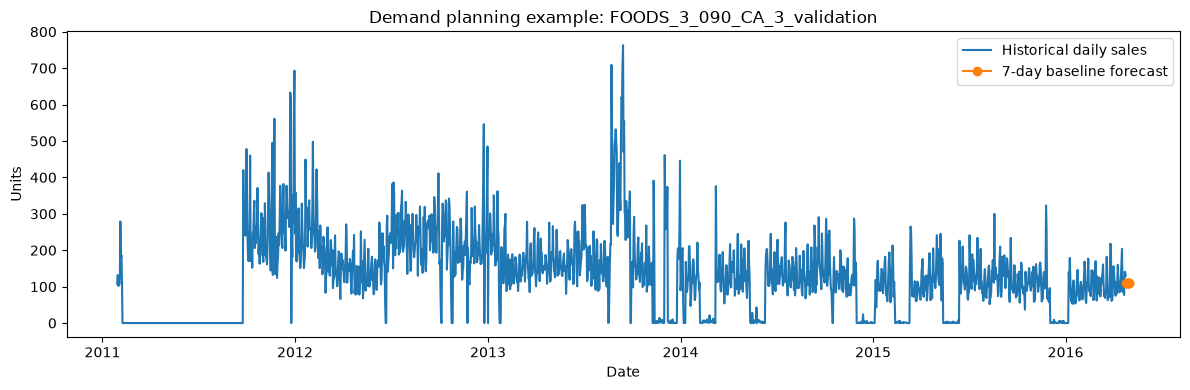

In [4]:
plt.figure(figsize=(12, 4))
plt.plot(example_sales["date"], example_sales["units_sold"], label="Historical daily sales")
forecast_dates = pd.date_range(example_sales["date"].max() + pd.Timedelta(days=1), periods=7)
plt.plot(forecast_dates, forecast["forecast_units"], marker="o", label="7-day baseline forecast")
plt.title(f"Demand planning example: {example_id}")
plt.xlabel("Date")
plt.ylabel("Units")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Calculate safety stock and reorder point

The reorder point answers: how much stock should be available when a new order is placed?

`Reorder point = average daily demand × lead time + safety stock`

`Safety stock = service-level multiplier × recent demand variation × √lead time`

In [5]:
safety_stock = service_level_multiplier * demand_std * np.sqrt(lead_time_days)
reorder_point = average_daily_demand * lead_time_days + safety_stock
cycle_stock = average_daily_demand * review_window_days
planning_summary = pd.DataFrame({
    "metric": ["Average daily demand", "Demand standard deviation", "Safety stock", "Reorder point", "28-day cycle stock"],
    "units": [average_daily_demand, demand_std, safety_stock, reorder_point, cycle_stock]
})
planning_summary.round(1)

,metric,units
0,Average daily demand,110.4
1,Demand standard deviation,34.8
2,Safety stock,151.9
3,Reorder point,924.4
4,28-day cycle stock,3090.0


## 5. Suggested replenishment quantity

If the item is reviewed every 7 days, the target stock level can cover the review period plus the lead time, with safety stock added. The suggested order quantity is the target level minus the current inventory position.

In [6]:
review_period_days = 7
target_stock = average_daily_demand * (lead_time_days + review_period_days) + safety_stock
current_inventory_position = 0
suggested_order_quantity = max(0, target_stock - current_inventory_position)
order_summary = pd.DataFrame({
    "metric": ["Target stock level", "Current inventory position", "Suggested order quantity"],
    "units": [target_stock, current_inventory_position, suggested_order_quantity]
})
order_summary.round(1)

,metric,units
0,Target stock level,1696.9
1,Current inventory position,0.0
2,Suggested order quantity,1696.9


## 6. Final conclusions

- A simple moving-average baseline can turn historical sales into a transparent short-term planning signal.
- The reorder point combines expected demand during lead time with a buffer for recent variability.
- A-items should be reviewed more frequently because an incorrect stock position has a larger operational impact.
- The suggested quantity is an example, not an automatic purchase order: current inventory, open orders, minimum order quantities, shelf life and supplier constraints must be added before execution.
- The next improvement would be to calculate the same metrics for every product-store combination and compare the results with actual stockouts and replenishment lead times.

This project therefore covers descriptive analytics and a practical, non-AI planning baseline.